# Recurrent neural net (RNN)

In [11]:
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, f1_score
import matplotlib.pyplot as plt
from pathlib import Path

In [12]:
# Initializing the data
features = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms', 'key', 'mode', 'time_signature']

data_dir = Path('data') if Path('data/train.csv').exists() else Path('../data')
train = pd.read_csv(data_dir / 'train.csv')
val = pd.read_csv(data_dir / 'validation.csv')
test = pd.read_csv(data_dir / 'test.csv')

genres = sorted(train['genre_group'].unique())
scaler = StandardScaler().fit(train[features])

In [13]:
# one feature per step (13 total-)
X_train = torch.tensor(scaler.transform(train[features]), dtype=torch.float32).unsqueeze(-1)
X_val = torch.tensor(scaler.transform(val[features]), dtype=torch.float32).unsqueeze(-1)
X_test = torch.tensor(scaler.transform(test[features]), dtype=torch.float32).unsqueeze(-1)

y_train = torch.tensor(train['genre_group'].map(genres.index).values)
y_val = torch.tensor(val['genre_group'].map(genres.index).values)
y_test = torch.tensor(test['genre_group'].map(genres.index).values)

loader = DataLoader(TensorDataset(X_train, y_train), batch_size=256, shuffle=True)

In [14]:
# rnn model 
class RNN(nn.Module):
    def __init__(self, hidden_size):
        super().__init__()
        self.rnn = nn.RNN(1, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, len(genres))

    def forward(self, x):
        _, h = self.rnn(x)
        return self.fc(h[-1])

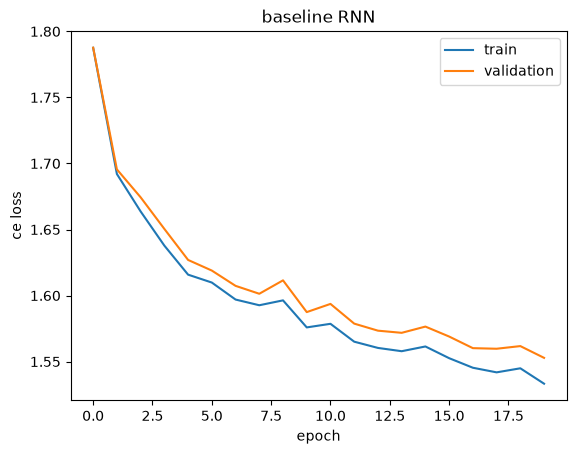

                      precision    recall  f1-score   support

chill_jazz_classical       0.51      0.64      0.57      1038
             country       0.40      0.21      0.27       293
    electronic_dance       0.56      0.71      0.62      1932
          hiphop_rnb       0.25      0.07      0.11       385
          indie_folk       0.55      0.02      0.05       251
               latin       0.40      0.51      0.45       917
                 pop       0.31      0.27      0.29      1096
              reggae       0.20      0.03      0.05       194
          rock_metal       0.50      0.59      0.54      1684
               world       0.28      0.13      0.18       789

            accuracy                           0.47      8579
           macro avg       0.39      0.32      0.31      8579
        weighted avg       0.44      0.47      0.43      8579



In [15]:
# Baseline with no class weights
torch.manual_seed(42)
model = RNN(64)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
train_losses, val_losses = [], []

for epoch in range(20):
    for X_batch, y_batch in loader:
        optimizer.zero_grad()
        loss = loss_fn(model(X_batch), y_batch)
        loss.backward()
        optimizer.step()

    with torch.no_grad():
        train_losses.append(loss_fn(model(X_train), y_train).item())
        val_losses.append(loss_fn(model(X_val), y_val).item())

plt.plot(train_losses, label='train')
plt.plot(val_losses, label='validation')
plt.title('baseline RNN')
plt.xlabel('epoch')
plt.ylabel('ce loss')
plt.legend()
plt.show()

with torch.no_grad():
    print(classification_report(y_val, model(X_val).argmax(1), target_names=genres))


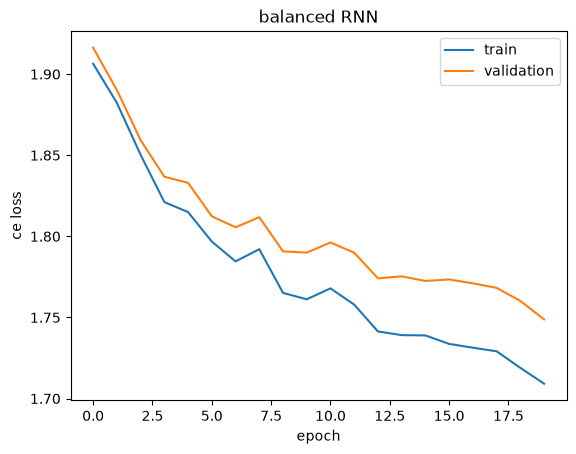

                      precision    recall  f1-score   support

chill_jazz_classical       0.53      0.59      0.56      1038
             country       0.22      0.52      0.30       293
    electronic_dance       0.68      0.53      0.59      1932
          hiphop_rnb       0.14      0.26      0.18       385
          indie_folk       0.12      0.36      0.18       251
               latin       0.48      0.37      0.42       917
                 pop       0.32      0.17      0.22      1096
              reggae       0.11      0.61      0.18       194
          rock_metal       0.59      0.39      0.47      1684
               world       0.21      0.06      0.10       789

            accuracy                           0.39      8579
           macro avg       0.34      0.39      0.32      8579
        weighted avg       0.46      0.39      0.40      8579



In [16]:
# Now with balancing on model 
counts = torch.bincount(y_train)
weights = len(y_train) / (len(genres) * counts.float())

torch.manual_seed(42)
model = RNN(64)
loss_fn = nn.CrossEntropyLoss(weight=weights)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
train_losses, val_losses = [], []

for epoch in range(20):
    for X_batch, y_batch in loader:
        optimizer.zero_grad()
        loss = loss_fn(model(X_batch), y_batch)
        loss.backward()
        optimizer.step()

    with torch.no_grad():
        train_losses.append(loss_fn(model(X_train), y_train).item())
        val_losses.append(loss_fn(model(X_val), y_val).item())

plt.plot(train_losses, label='train')
plt.plot(val_losses, label='validation')
plt.title('balanced RNN')
plt.xlabel('epoch')
plt.ylabel('ce loss')
plt.legend()
plt.show()

with torch.no_grad():
    print(classification_report(y_val, model(X_val).argmax(1), target_names=genres))

In [17]:
# trying to find best hidden size & learning rate, then finetune

best_score = 0
best_params = None

for hidden in [32, 64, 128]:
    for lr in [0.01, 0.001]:
        torch.manual_seed(42)
        model = RNN(hidden)
        loss_fn = nn.CrossEntropyLoss(weight=weights)
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)

        for epoch in range(20):
            for X_batch, y_batch in loader:
                optimizer.zero_grad()
                loss = loss_fn(model(X_batch), y_batch)
                loss.backward()
                optimizer.step()

        with torch.no_grad():
            score = f1_score(y_val, model(X_val).argmax(1), average='macro')
        print(f"hidden size ={hidden:<4} lr = {lr:<6} macro F1 score = {score:.3f}")

        if score > best_score:
            best_score = score
            best_params = (hidden, lr)

print("\n best param: ", best_params, f" score: {best_score:.3f}")

hidden size =32   lr = 0.01   macro F1 score = 0.299
hidden size =32   lr = 0.001  macro F1 score = 0.312
hidden size =64   lr = 0.01   macro F1 score = 0.166
hidden size =64   lr = 0.001  macro F1 score = 0.321
hidden size =128  lr = 0.01   macro F1 score = 0.072
hidden size =128  lr = 0.001  macro F1 score = 0.349

 best param:  (128, 0.001)  score: 0.349


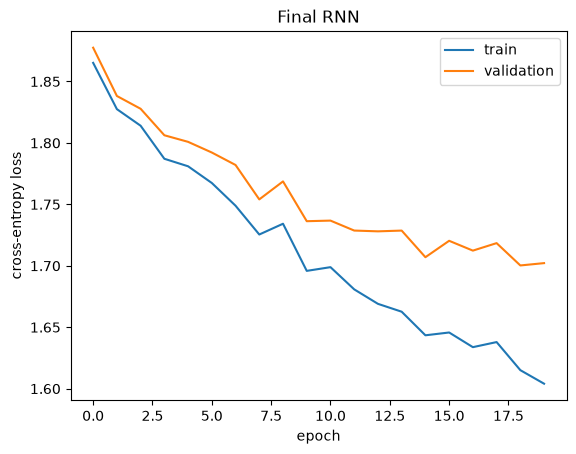

                      precision    recall  f1-score   support

chill_jazz_classical       0.59      0.58      0.58      1038
             country       0.20      0.66      0.31       293
    electronic_dance       0.69      0.56      0.62      1932
          hiphop_rnb       0.21      0.25      0.23       385
          indie_folk       0.13      0.45      0.20       251
               latin       0.56      0.36      0.44       917
                 pop       0.38      0.18      0.25      1096
              reggae       0.12      0.59      0.19       194
          rock_metal       0.60      0.43      0.50      1684
               world       0.27      0.13      0.17       789

            accuracy                           0.41      8579
           macro avg       0.37      0.42      0.35      8579
        weighted avg       0.50      0.41      0.43      8579



In [18]:
# results (initially had size 64, but best param is 128, finetune to it)
torch.manual_seed(42)
model = RNN(128)  # put in the best hidden size from tuning
loss_fn = nn.CrossEntropyLoss(weight=weights)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)  # putting in the best lr from tuning
train_losses, val_losses = [], []

for epoch in range(20):
    for X_batch, y_batch in loader:
        optimizer.zero_grad()
        loss = loss_fn(model(X_batch), y_batch)
        loss.backward()
        optimizer.step()

    with torch.no_grad():
        train_losses.append(loss_fn(model(X_train), y_train).item())
        val_losses.append(loss_fn(model(X_val), y_val).item())

plt.plot(train_losses, label='train')
plt.plot(val_losses, label='validation')
plt.title('Final RNN')
plt.xlabel('epoch')
plt.ylabel('cross-entropy loss')
plt.legend()
plt.show()

with torch.no_grad():
    print(classification_report(y_val, model(X_val).argmax(1), target_names=genres))

In [19]:
# With test set
with torch.no_grad():
    print(classification_report(y_test, model(X_test).argmax(1), target_names=genres))

                      precision    recall  f1-score   support

chill_jazz_classical       0.62      0.60      0.61      1038
             country       0.21      0.68      0.32       292
    electronic_dance       0.69      0.56      0.61      1932
          hiphop_rnb       0.20      0.25      0.23       385
          indie_folk       0.12      0.42      0.19       250
               latin       0.58      0.39      0.47       918
                 pop       0.34      0.16      0.22      1097
              reggae       0.11      0.57      0.18       194
          rock_metal       0.62      0.44      0.52      1685
               world       0.31      0.16      0.21       789

            accuracy                           0.42      8580
           macro avg       0.38      0.42      0.35      8580
        weighted avg       0.51      0.42      0.44      8580

